In [1]:
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [ ]:
df = pd.read_parquet("taxi_trips.parquet")

features = [
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "min_of_day",
    "day_of_week",
    "day_of_year",
]

X = df[features].to_numpy(dtype=np.float32)
y = df["trip_duration"].to_numpy(dtype=np.float32)

print("Shape:", X.shape, y.shape)
print(df["trip_duration"].describe())

assert np.isfinite(X).all(), "Inputs contain missing or infinite values."
assert np.isfinite(y).all(), "Targets contain missing or infinite values."

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

print("Train:", len(y_train))
print("Validation:", len(y_val))
print("Test:", len(y_test))

Shape: (523554, 7) (523554,)
count    523554.000000
mean         10.413046
std           7.754068
min           0.033386
25%           4.749882
50%           8.631456
75%          13.928152
max         227.942612
Name: trip_duration, dtype: float64
Train: 366487
Validation: 78533
Test: 78534


In [ ]:
def regression_metrics(y, mu, sigma):
    """Gaussian NLL without the constant, and RMSE."""
    y = np.asarray(y, dtype=np.float64)
    mu = np.asarray(mu, dtype=np.float64)
    sigma = np.asarray(sigma, dtype=np.float64)

    nll = np.mean(
        np.log(sigma) + 0.5 * ((y - mu) / sigma) ** 2
    )
    rmse = np.sqrt(np.mean((y - mu) ** 2))

    return {"NLL": float(nll), "RMSE": float(rmse)}


constant_mu = float(np.mean(y_train))
constant_sigma = max(float(np.std(y_train, ddof=0)), 1e-6)

linear = LinearRegression()
linear.fit(X_train, y_train)

train_residuals = (
    y_train.astype(np.float64) - linear.predict(X_train)
)
linear_sigma = max(
    float(np.sqrt(np.mean(train_residuals ** 2))),
    1e-6,
)

baseline_val = pd.DataFrame({
    "Constant Gaussian": regression_metrics(
        y_val, constant_mu, constant_sigma
    ),
    "Linear Gaussian": regression_metrics(
        y_val, linear.predict(X_val), linear_sigma
    ),
}).T

baseline_val

,NLL,RMSE
Constant Gaussian,2.547129,7.745618
Linear Gaussian,2.517967,7.522955


In [ ]:
class GaussianMLP(nn.Module):
    def __init__(self, d_in=7):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_in, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        out = self.net(x)
        mu = out[:, 0]
        log_sigma = out[:, 1]
        return mu, log_sigma


def gaussian_nll(mu, log_sigma, y):
    return (
        log_sigma
        + 0.5 * (y - mu).square() * torch.exp(-2 * log_sigma)
    ).mean()


model = GaussianMLP(d_in=X_train.shape[1]).to(device)

with torch.no_grad():
    model.net[-1].bias.copy_(
        torch.tensor(
            [constant_mu, np.log(constant_sigma)],
            dtype=torch.float32,
            device=device,
        )
    )

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
def make_loader(X, y, batch_size, shuffle=False):
    dataset = TensorDataset(
        torch.from_numpy(X),
        torch.from_numpy(y),
    )
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
    )


train_loader = make_loader(X_train, y_train, 256, shuffle=True)
val_loader = make_loader(X_val, y_val, 4096)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_nll = 0.0
    total_squared_error = 0.0
    n = 0

    for xb, yb in loader:
        xb = xb.to(device)
        yb = yb.to(device)

        mu, log_sigma = model(xb)
        batch_n = len(yb)

        total_nll += gaussian_nll(
            mu, log_sigma, yb
        ).item() * batch_n

        total_squared_error += (
            (yb - mu).square().sum().item()
        )
        n += batch_n

    return {
        "NLL": total_nll / n,
        "RMSE": np.sqrt(total_squared_error / n),
    }


max_epochs = 200
patience = 15
best_val_nll = float("inf")
best_state = None
best_epoch = None
waiting = 0
history = []

for epoch in range(1, max_epochs + 1):
    model.train()

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        mu, log_sigma = model(xb)
        loss = gaussian_nll(mu, log_sigma, yb)

        if not torch.isfinite(loss):
            raise RuntimeError(
                "Non-finite loss. Check data, outputs, and learning rate."
            )

        loss.backward()
        optimizer.step()

    train_metrics = evaluate(model, train_loader)
    val_metrics = evaluate(model, val_loader)

    history.append({
        "epoch": epoch,
        "train_nll": train_metrics["NLL"],
        "val_nll": val_metrics["NLL"],
    })

    if val_metrics["NLL"] < best_val_nll:
        best_val_nll = val_metrics["NLL"]
        best_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train NLL: {train_metrics['NLL']:.4f} | "
            f"val NLL: {val_metrics['NLL']:.4f}"
        )

    if waiting >= patience:
        print("Early stopping.")
        break

model.load_state_dict(best_state)
print("Best epoch:", best_epoch)
print("Best validation NLL:", best_val_nll)

Epoch   1 | train NLL: 1.8806 | val NLL: 1.8876
Epoch  10 | train NLL: 1.7453 | val NLL: 1.7607
Epoch  20 | train NLL: 1.7191 | val NLL: 1.7372
Epoch  30 | train NLL: 1.6963 | val NLL: 1.7265
Epoch  40 | train NLL: 1.6844 | val NLL: 1.7173
Epoch  50 | train NLL: 1.6639 | val NLL: 1.7086
Epoch  60 | train NLL: 1.6646 | val NLL: 1.7261
Epoch  70 | train NLL: 1.6776 | val NLL: 1.7162
Epoch  80 | train NLL: 1.6538 | val NLL: 1.7047
Epoch  90 | train NLL: 1.6466 | val NLL: 1.7097
Epoch 100 | train NLL: 1.6431 | val NLL: 1.7014
Epoch 110 | train NLL: 1.6342 | val NLL: 1.7082
Epoch 120 | train NLL: 1.6454 | val NLL: 1.7001
Early stopping.
Best epoch: 109
Best validation NLL: 1.6918569521764157


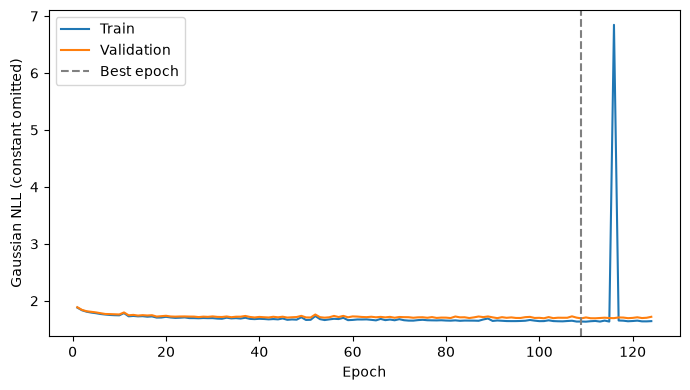

In [6]:
history_df = pd.DataFrame(history)

plt.figure(figsize=(7, 4))
plt.plot(
    history_df["epoch"],
    history_df["train_nll"],
    label="Train",
)
plt.plot(
    history_df["epoch"],
    history_df["val_nll"],
    label="Validation",
)
plt.axvline(
    best_epoch,
    color="gray",
    linestyle="--",
    label="Best epoch",
)
plt.xlabel("Epoch")
plt.ylabel("Gaussian NLL (constant omitted)")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
test_loader = make_loader(X_test, y_test, 4096)

rows = []

for name, predict_mu, sigma in [
    (
        "Constant Gaussian",
        lambda X: np.full(len(X), constant_mu),
        constant_sigma,
    ),
    (
        "Linear Gaussian",
        linear.predict,
        linear_sigma,
    ),
]:
    val = regression_metrics(y_val, predict_mu(X_val), sigma)
    test = regression_metrics(y_test, predict_mu(X_test), sigma)

    rows.append({
        "Model": name,
        "Validation NLL": val["NLL"],
        "Test NLL": test["NLL"],
        "Test RMSE (minutes)": test["RMSE"],
    })

val = evaluate(model, val_loader)
test = evaluate(model, test_loader)

rows.append({
    "Model": "Gaussian MLP",
    "Validation NLL": val["NLL"],
    "Test NLL": test["NLL"],
    "Test RMSE (minutes)": test["RMSE"],
})

results = pd.DataFrame(rows).set_index("Model")
results

,Validation NLL,Test NLL,Test RMSE (minutes)
Model,,,
Constant Gaussian,2.547129,2.548582,7.756892
Linear Gaussian,2.517967,2.520814,7.544462
Gaussian MLP,1.691857,1.855338,3.949131


In [ ]:
from sklearn.metrics import brier_score_loss, accuracy_score

@torch.no_grad()
def predict_under_45(model, loader):
    model.eval()
    probabilities = []

    standard_normal = torch.distributions.Normal(0.0, 1.0)

    for xb, _ in loader:
        xb = xb.to(device)

        mu, log_sigma = model(xb)
        standardized_threshold = (
            (45.0 - mu) * torch.exp(-log_sigma)
        )

        p = standard_normal.cdf(standardized_threshold)
        probabilities.append(p.cpu().numpy())

    return np.concatenate(probabilities)


test_loader = make_loader(
    X_test, y_test, batch_size=4096, shuffle=False
)

p_test = predict_under_45(model, test_loader)
z_test = (y_test < 45).astype(int)
pred_test = (p_test >= 0.5).astype(int)

print("Test Brier score:", brier_score_loss(z_test, p_test))
print("Test accuracy:", accuracy_score(z_test, pred_test))
print("Fraction of trips under 45 minutes:", z_test.mean())

Test Brier score: 0.002781796036288142
Test accuracy: 0.9968166653933328
Fraction of trips under 45 minutes: 0.995543331550666


In [ ]:
from scipy.special import ndtr

p_constant = np.full(
    len(y_test),
    ndtr((45.0 - constant_mu) / constant_sigma),
)

p_linear = ndtr(
    (45.0 - linear.predict(X_test)) / linear_sigma
)

train_event_rate = np.mean(y_train < 45)
p_event_rate = np.full(len(y_test), train_event_rate)

probability_results = pd.DataFrame([
    {
        "Model": name,
        "Brier score": brier_score_loss(z_test, p),
        "Accuracy": accuracy_score(
            z_test, (p >= 0.5).astype(int)
        ),
    }
    for name, p in [
        ("Constant event rate", p_event_rate),
        ("Constant Gaussian", p_constant),
        ("Linear Gaussian", p_linear),
        ("Gaussian MLP", p_test),
    ]
]).set_index("Model")

probability_results

,Brier score,Accuracy
Model,,
Constant event rate,0.004437,0.995543
Constant Gaussian,0.004457,0.995543
Linear Gaussian,0.004455,0.995543
Gaussian MLP,0.002782,0.996817
